**Partie Video**

# Preparation fichiers

In [ ]:
import os
import numpy as np
import pandas as pd

# Dossier contenant les données nécessaires à la fusion
DATA_PATH = "/content/data"

Extraction terminée !


In [ ]:
import os

dossier_video = "/content/data/movie/video"

fichiers = os.listdir(dossier_video)

print("Nombre total d'éléments :", len(fichiers))
print("\nPremiers éléments :")

for nom in fichiers[:15]:
    chemin = os.path.join(dossier_video, nom)
    if os.path.isdir(chemin):
        print("📁", nom)
    else:
        print("📄", nom)

Nombre total d'éléments : 351

Premiers éléments :
📁 00250
📁 00180
📁 00305
📁 00273
📁 00237
📁 00132
📁 00128
📁 00361
📁 00312
📁 00276
📁 00182
📁 00078
📁 00137
📁 00310
📁 00345


**Vérifier l’organisation des vidéos et trouver les fichiers JSON**

In [ ]:
base_path = "/content/data/movie"

total_mp4 = 0
total_json = 0
exemples_mp4 = []
exemples_json = []

for racine, dossiers, fichiers in os.walk(base_path):
    for fichier in fichiers:
        chemin = os.path.join(racine, fichier)
        extension = os.path.splitext(fichier)[1].lower()

        if extension == ".mp4":
            total_mp4 += 1
            if len(exemples_mp4) < 10:
                exemples_mp4.append(chemin)

        elif extension == ".json":
            total_json += 1
            if len(exemples_json) < 10:
                exemples_json.append(chemin)

print("Nombre total de vidéos MP4 :", total_mp4)
print("Nombre total de fichiers JSON :", total_json)

print("\nExemples de vidéos :")
for chemin in exemples_mp4:
    print(chemin)

print("\nExemples de fichiers JSON :")
for chemin in exemples_json:
    print(chemin)


Nombre total de vidéos MP4 : 3088
Nombre total de fichiers JSON : 3088

Exemples de vidéos :
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00250/00250_clip_002.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00250/00250_clip_010.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00250/00250_clip_006.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00250/00250_clip_011.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_002.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_017.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_004.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_005.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_003.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_014.mp4

Exemples de fichiers JSON :
/content/PROJET_SID_2026/PROJET_SID_2026/movie/annotation/00250/00250_clip_002.json
/content/PROJE

**Examiner un JSON proprement afin de comprendre les informations disponibles pour chaque clip.**

In [ ]:
import json

json_path = os.path.join(
    base_path,"movie","annotation","00111","00111_clip_013.json")
with open(json_path, "r", encoding="utf-8") as f:
    data = json.load(f)

print("Type de données :", type(data).__name__)
print("\nContenu du JSON :")
print(json.dumps(data, indent=2, ensure_ascii=False)[:6000])

Type de données : dict

Contenu du JSON :
{
  "video_id": "00111_clip_013",
  "brightness": 0.1,
  "colorfulness": 0.4,
  "hue": 16,
  "emotion": "contentment",
  "caption": "In this scene, a man and a woman are engaged in a conversation. The man, dressed in a black suit with a white shirt and a bow tie, is adjusting the woman's bow tie. The woman, wearing a black dress with a high collar, is looking at the man with a smile. The background is dark and blurry, suggesting an indoor setting.",
  "duration": 4.84
}


**Vérifier les noms des fichiers vidéo et des fichiers JSON pour si ils correspondent bien**

In [ ]:
import pandas as pd

base_path = "/content/data/movie"
video_path = os.path.join(base_path, "movie", "video")

videos = []

for racine, _, fichiers in os.walk(video_path):
    for fichier in fichiers:
        if fichier.lower().endswith(".mp4"):
            video_id = os.path.splitext(fichier)[0]
            chemin = os.path.join(racine, fichier)

            videos.append({
                "video_id": video_id,
                "video_path": chemin
            })

df_videos = pd.DataFrame(videos)
df_videos = df_videos.sort_values("video_id").reset_index(drop=True)

print("Nombre total de vidéos :", len(df_videos))
print("\nAperçu :")
print(df_videos.head(10).to_string(index=False))

Nombre total de vidéos : 3088

Aperçu :
      video_id                                                                    video_path
00000_clip_001 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_001.mp4
00000_clip_002 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_002.mp4
00000_clip_006 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_006.mp4
00000_clip_009 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_009.mp4
00000_clip_012 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_012.mp4
00000_clip_035 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_035.mp4
00000_clip_037 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_037.mp4
00000_clip_040 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_040.mp4
00000_clip_046 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_046.mp4
00000_clip_055 /content/PROJET

**Sauvegarder les identifiants**

In [ ]:
ids_video = df_videos[["video_id"]].copy()

output_path = "/content/ids_video.csv"

ids_video.to_csv(output_path, index=False)

print("Fichier créé :", output_path)
print("Nombre d'identifiants :", len(ids_video))
print("\nAperçu du fichier :")
print(ids_video.head(10).to_string(index=False))

Fichier créé : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /ids_video.csv
Nombre d'identifiants : 3088

Aperçu du fichier :
      video_id
00000_clip_001
00000_clip_002
00000_clip_006
00000_clip_009
00000_clip_012
00000_clip_035
00000_clip_037
00000_clip_040
00000_clip_046
00000_clip_055


**Vérifier les identifiants en double**

In [ ]:
doublons = df_videos[
    df_videos["video_id"].duplicated(keep=False)
].sort_values("video_id")

print("Nombre total de vidéos :", len(df_videos))
print("Nombre d'identifiants en double :", doublons["video_id"].nunique())
print("Nombre de fichiers concernés :", len(doublons))

display(doublons)

Nombre total de vidéos : 3088
Nombre d'identifiants en double : 0
Nombre de fichiers concernés : 0


,video_id,video_path


**Vérifier la lisibilité des vidéos**

In [ ]:
import cv2
def lisible(chemin):
    cap = cv2.VideoCapture(chemin)
    ok, image = cap.read()
    cap.release()
    return ok

df_videos["mp4_lisible"] = df_videos["video_path"].apply(lisible)
print("Nombre total de vidéos :", len(df_videos))
print("Nombre de vidéos illisibles :", (~df_videos["mp4_lisible"]).sum())

Nombre total de vidéos : 3088
Nombre de vidéos illisibles : 0


Les 3 088 fichiers vidéo ont été testés avec OpenCV. Aucune vidéo illisible n’a été détectée : le programme a réussi à lire au moins une image dans chaque fichier.

**Vérifier les informations disponibles sur les vidéos**

In [ ]:
print("Colonnes disponibles :")
print(df_videos.columns.tolist())
display(df_videos.head())
print("\nValeurs manquantes par colonne :")
print(df_videos.isna().sum())

Colonnes disponibles :
['video_id', 'video_path']


,video_id,video_path
0,00000_clip_001,/content/PROJET_SID_2026/PROJET_SID_2026/movie...
1,00000_clip_002,/content/PROJET_SID_2026/PROJET_SID_2026/movie...
2,00000_clip_006,/content/PROJET_SID_2026/PROJET_SID_2026/movie...
3,00000_clip_009,/content/PROJET_SID_2026/PROJET_SID_2026/movie...
4,00000_clip_012,/content/PROJET_SID_2026/PROJET_SID_2026/movie...



Valeurs manquantes par colonne :
video_id      0
video_path    0
dtype: int64


In [ ]:
print("Nombre de vidéos :", len(df_videos))
print("Identifiants vidéo dupliqués :",df_videos["video_id"].duplicated().sum())
print("Chemins vidéo dupliqués :",df_videos["video_path"].duplicated().sum())
print("Valeurs manquantes :")
print(df_videos.isna().sum())

Nombre de vidéos : 3088
Identifiants vidéo dupliqués : 0
Chemins vidéo dupliqués : 0
Valeurs manquantes :
video_id       0
video_path     0
mp4_lisible    0
dtype: int64


**Vérifier la répartition des vidéos**

In [ ]:
df_videos["dossier"] = df_videos["video_path"].apply(lambda chemin: os.path.basename(os.path.dirname(chemin)))
print(df_videos["dossier"].value_counts().sort_index().to_string())

dossier
00000    17
00002    14
00003     8
00004    11
00005    11
00006    11
00007    10
00008     7
00009     8
00012    11
00013    11
00014     8
00015    10
00016    10
00017    14
00018    13
00019     6
00020    11
00021     5
00022    12
00023     6
00024     6
00025     6
00026     7
00027     8
00028    12
00029    11
00030     9
00031    11
00032     7
00033     9
00034     7
00035     7
00036     4
00037     7
00038     7
00039     8
00040     9
00041     7
00042     6
00044     8
00045    12
00046     6
00047    14
00048     9
00049     8
00050     8
00051    11
00052     8
00053    15
00054     7
00055     8
00056    17
00057    11
00058     6
00059     8
00060    14
00061    10
00062     9
00063     8
00064    13
00065     4
00066     9
00069    13
00070     6
00072     5
00073     4
00074    11
00075     6
00076    10
00077    10
00078     6
00079     9
00080    10
00081     8
00082     6
00083     8
00084     7
00085     7
00086     7
00087     9
00088     5
00089   

In [ ]:
dossier_splits = "/content/splits"
def lire_identifiants(nom_fichier):
    chemin = os.path.join(dossier_splits, nom_fichier + ".txt")
    with open(chemin, "r", encoding="utf-8") as fichier:
        return set(ligne.strip() for ligne in fichier if ligne.strip())

train_ids = lire_identifiants("train")
dev_ids = lire_identifiants("dev")
test_ids = lire_identifiants("test")

print("Train :", len(train_ids))
print("Dev :", len(dev_ids))
print("Test :", len(test_ids))

Train : 250
Dev : 50
Test : 50


In [ ]:
print("Nombre de lignes dans df_videos :", len(df_videos))
print("Nombre de dossiers uniques :", df_videos["dossier"].nunique())
print("Premiers dossiers :", df_videos["dossier"].unique()[:15])
print("Premiers identifiants train :", sorted(train_ids)[:15])

Nombre de lignes dans df_videos : 3088
Nombre de dossiers uniques : 350
Premiers dossiers : ['00000' '00002' '00003' '00004' '00005' '00006' '00007' '00008' '00009'
 '00012' '00013' '00014' '00015' '00016' '00017']
Premiers identifiants train : ['00002', '00004', '00005', '00006', '00007', '00012', '00013', '00014', '00016', '00017', '00018', '00021', '00023', '00024', '00025']


In [ ]:
dossier = dossier_splits

for nom in ["train.txt", "dev.txt", "test.txt"]:
    chemin = os.path.join(dossier, nom)
    with open(chemin, "r", encoding="utf-8") as fichier:
        lignes = fichier.readlines()
    print(f"\n--- {nom} ---")
    print("Nombre de lignes :", len(lignes))
    print("Premières lignes :")
    print("".join(lignes[:5]))


--- train.txt ---
Nombre de lignes : 250
Premières lignes :
00002
00004
00005
00006
00007


--- dev.txt ---
Nombre de lignes : 50
Premières lignes :
00008
00015
00020
00026
00040


--- test.txt ---
Nombre de lignes : 50
Premières lignes :
00000
00003
00009
00019
00022



**associer les vidéos à leur reapartion dev train test**

In [ ]:
#lire les identifiants de chaque groupe
with open(os.path.join(dossier, "train.txt"), "r", encoding="utf-8") as f:
    train_ids = set(ligne.strip() for ligne in f if ligne.strip())

with open(os.path.join(dossier, "dev.txt"), "r", encoding="utf-8") as f:
    dev_ids = set(ligne.strip() for ligne in f if ligne.strip())

with open(os.path.join(dossier, "test.txt"), "r", encoding="utf-8") as f:
    test_ids = set(ligne.strip() for ligne in f if ligne.strip())

#identifier le dossier de chaque vidéo
df_videos["dossier"] = df_videos["video_path"].apply(
    lambda chemin: os.path.basename(os.path.dirname(chemin))
)
#associer chaque vidéo à son groupe
def trouver_split(identifiant):
    if identifiant in train_ids:
        return "train"
    elif identifiant in dev_ids:
        return "dev"
    elif identifiant in test_ids:
        return "test"
    else:
        return "non_attribue"

df_videos["split"] = df_videos["dossier"].apply(trouver_split)

print("Nombre de vidéos par groupe :")
print(df_videos["split"].value_counts())

print("\nExemples :")
display(df_videos[["video_id", "dossier", "split"]].head(10))

Nombre de vidéos par groupe :
split
train    2207
dev       442
test      439
Name: count, dtype: int64

Exemples :


,video_id,dossier,split
0,00000_clip_001,00000,test
1,00000_clip_002,00000,test
2,00000_clip_006,00000,test
3,00000_clip_009,00000,test
4,00000_clip_012,00000,test
5,00000_clip_035,00000,test
6,00000_clip_037,00000,test
7,00000_clip_040,00000,test
8,00000_clip_046,00000,test
9,00000_clip_055,00000,test


In [ ]:
import pandas as pd
cv_path = "/content/ids_video.csv"
print("Le fichier existe :", os.path.exists(csv_path))
if os.path.exists(csv_path):
    ids_csv = pd.read_csv(csv_path)
    print("Nombre d'identifiants :", len(ids_csv))
    print("Colonnes :", ids_csv.columns.tolist())
    print("Identifiants dupliqués :", ids_csv["video_id"].duplicated().sum())
    display(ids_csv.head())

Le fichier existe : True
Nombre d'identifiants : 3088
Colonnes : ['video_id']
Identifiants dupliqués : 0


,video_id
0,00000_clip_001
1,00000_clip_002
2,00000_clip_006
3,00000_clip_009
4,00000_clip_012


# Extraire les videos Avec Open CV

**Lire les vidéos et extraire les images**

***Tester l’extraction sur une vidéo***

lire une vidéo ;
choisir 8 images réparties dans la vidéo ;
essayer une image voisine si la lecture échoue ;
convertir les images en RGB ;
conserver les images dans images_rgb et les afficher

Vidéo : 00002_clip_004
Partition : train
Nombre d'images : 115
FPS : 23.98
Durée : 4.8 secondes
Images extraites : 8
Positions échouées : []


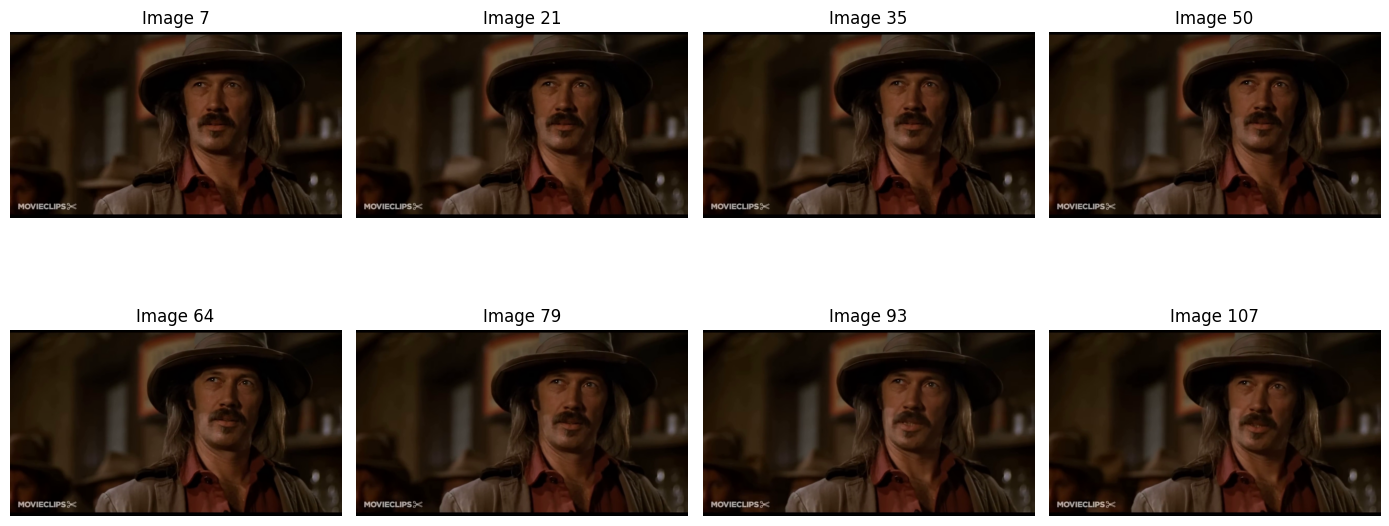

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Choisir une vidéo du groupe train
video = df_videos[df_videos["split"] == "train"].iloc[0]
chemin_video = video["video_path"]

print("Vidéo :", video["video_id"])
print("Partition :", video["split"])

# Ouvrir la vidéo
cap = cv2.VideoCapture(chemin_video)

if cap.isOpened():
    fps = cap.get(cv2.CAP_PROP_FPS)
    nb_images = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duree = nb_images / fps if fps > 0 else 0

    print("Nombre d'images :", nb_images)
    print("FPS :", round(fps, 2))
    print("Durée :", round(duree, 2), "secondes")

    if nb_images > 0:
        # Choisir 8 images réparties dans la vidéo
        positions = (
            (np.arange(8) + 0.5) * nb_images / 8
        ).astype(int)

        images_rgb = []
        positions_echouees = []

        for pos in positions:
            image_rgb = None

            # Si la lecture échoue, essayer une image voisine
            for p in [pos, pos + 1, pos - 1]:
                if 0 <= p < nb_images:
                    cap.set(cv2.CAP_PROP_POS_FRAMES, p)
                    succes, image = cap.read()

                    if succes and image is not None:
                        image_rgb = cv2.cvtColor(
                            image, cv2.COLOR_BGR2RGB
                        )
                        break

            if image_rgb is not None:
                images_rgb.append((pos, image_rgb))
            else:
                positions_echouees.append(pos)

        cap.release()

        print("Images extraites :", len(images_rgb))
        print("Positions échouées :", positions_echouees)

        # Afficher les images
        fig, axes = plt.subplots(2, 4, figsize=(14, 7))

        for ax in axes.flat:
            ax.axis("off")

        for ax, (pos, image_rgb) in zip(axes.flat, images_rgb):
            ax.imshow(image_rgb)
            ax.set_title(f"Image {pos}")

        plt.tight_layout()
        plt.show()

    else:
        cap.release()
        print("Nombre d'images indisponible.")

else:
    print("Impossible d'ouvrir la vidéo.")

Le test sur la vidéo 00002_clip_004 a réussi. La vidéo dure 4,8 secondes et contient 115 images. Les 8 images ont été extraites sans erreur. Nous pouvons maintenant passer à l’extraction des images de toutes les vidéos.

In [ ]:
def extraire_images(chemin_video, n=8):

    cap = cv2.VideoCapture(chemin_video)

    info = {
        "statut": "échec",
        "nb_images": 0,
        "fps": 0,
        "duree": 0,
        "positions_echouees": []
    }

    images_rgb = []

    if not cap.isOpened():
        info["statut"] = "vidéo illisible"
        return images_rgb, info

    fps = cap.get(cv2.CAP_PROP_FPS)
    nb_images = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    duree = nb_images / fps if fps > 0 else 0

    info["nb_images"] = nb_images
    info["fps"] = round(fps, 2)
    info["duree"] = round(duree, 2)

    if nb_images <= 0:
        info["statut"] = "aucune image"
        cap.release()
        return images_rgb, info

    positions = (
        (np.arange(n) + 0.5) * nb_images / n
    ).astype(int)

    for pos in positions:

        image_rgb = None

        for p in [pos, pos + 1, pos - 1]:

            if 0 <= p < nb_images:
                cap.set(cv2.CAP_PROP_POS_FRAMES, p)
                succes, image = cap.read()

                if succes and image is not None:
                    image_rgb = cv2.cvtColor(
                        image, cv2.COLOR_BGR2RGB
                    )
                    break

        if image_rgb is not None:
            images_rgb.append(image_rgb)
        else:
            info["positions_echouees"].append(pos)

    cap.release()

    info["nb_images_extraites"] = len(images_rgb)

    if len(images_rgb) == n:
        info["statut"] = "succès"
    elif len(images_rgb) > 0:
        info["statut"] = "partiel"

    return images_rgb, info

Tester sur 20 videos

In [ ]:
# import time
# #tester sur 20 vidéos du groupe train
# videos_test = df_videos[df_videos["split"] == "train"].head(20)

# resultats = []
# cache = {}
# debut = time.time()

# for _, video in videos_test.iterrows():
#     debut_video = time.time()

#     images, info = extraire_images(video["video_path"])

#     info["video_id"] = video["video_id"]
#     info["temps_s"] = round(time.time() - debut_video, 2)

#     resultats.append(info)
#     cache[video["video_id"]] = images

# #afficher les résultats
# df_test = pd.DataFrame(resultats)
# display(df_test)

# print("Bilan :")
# print(df_test["statut"].value_counts())

# print("Temps total :", round(time.time() - debut, 2), "secondes")
# print("Temps moyen par vidéo :", round(df_test["temps_s"].mean(), 2), "secondes")
# print("Estimation pour 3088 vidéos :",round(df_test["temps_s"].mean() * 3088 / 60, 1),"minutes")

Nous avons testé l’extraction sur 20 vidéos. Pour chaque vidéo, nous avons extrait 8 images avec le temps moyen est de 3,69 secondes par vidéo.

***vérifier que les images sont bien conservées***

In [ ]:
# print("Nombre de vidéos :", len(cache))
# print("Images extraites pour la première vidéo :",len(cache["00002_clip_004"]))
# print("Taille d'une image :",cache["00002_clip_004"][0].shape)

In [ ]:
#dossier pour enregistrer les images
dossier_images = "/content/images_test"
os.makedirs(dossier_images, exist_ok=True)

#enregistrer les images de chaque vidéo
for video_id, images in cache.items():
    dossier_video = os.path.join(dossier_images, video_id)
    os.makedirs(dossier_video, exist_ok=True)

    for i, image_rgb in enumerate(images):
        image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
        chemin = os.path.join(dossier_video, f"image_{i+1}.jpg")
        cv2.imwrite(chemin, image_bgr)

print("Sauvegarde terminée.")
print("Dossier :", dossier_images)

Sauvegarde terminée.
Dossier : /content/drive/MyDrive/Projet Multimédia/Fatima ez zahra /Video/images_test


In [ ]:
nb_dossiers = 0
nb_images = 0
for video_id in cache:
    dossier_video = os.path.join(dossier_images, video_id)

    if os.path.isdir(dossier_video):
        nb_dossiers += 1
        nb_images += len([
            f for f in os.listdir(dossier_video)
            if f.endswith(".jpg")
        ])

print("Dossiers de vidéos :", nb_dossiers)
print("Images enregistrées :", nb_images)

Dossiers de vidéos : 4
Images enregistrées : 32


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

#choisir une vidéo de test
video_id = "00002_clip_004"

#chemin de la première image enregistrée
chemin_image = os.path.join(dossier_images,video_id,"image_1.jpg")

#ouvrir et afficher l'image
image = Image.open(chemin_image)

print("Image trouvée :", os.path.exists(chemin_image))
print("Taille de l'image :", image.size)
print("Mode :", image.mode)

plt.imshow(image)
plt.axis("off")
plt.show()

**Réduire la dimension d'une image**

In [ ]:
def redimensionner(img, cible=224):
    hauteur, largeur = img.shape[:2]
    facteur = cible / min(hauteur, largeur)
    nouvelle_largeur = round(largeur * facteur)
    nouvelle_hauteur = round(hauteur * facteur)
    return cv2.resize(img,(nouvelle_largeur, nouvelle_hauteur),interpolation=cv2.INTER_AREA)

In [ ]:
print("Nombre de vidéos :", len(df_videos))
print("Colonnes :", df_videos.columns.tolist())
print("Fonction d'extraction :", callable(extraire_images))
print("Fonction de redimensionnement :", callable(redimensionner))

#dossier pour enregistrer les fichiers NPY
dossier_npy = "/content/data/extraction_complete/images_npy"
os.makedirs(dossier_npy, exist_ok=True)

#fichier pour suivre l'extraction
fichier_suivi = "/content/data/extraction_complete/suivi_extraction.csv"

print("Dossier de sauvegarde créé :", os.path.isdir(dossier_npy))
print("Chemin du fichier de suivi :", fichier_suivi)

Nombre de vidéos : 3088
Colonnes : ['video_id', 'video_path', 'mp4_lisible', 'dossier', 'split']
Fonction d'extraction : True
Fonction de redimensionnement : True
Dossier de sauvegarde créé : True
Chemin du fichier de suivi : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/extraction_complete/suivi_extraction.csv


Vérifier si extraction et redimension fonctionne sans creer un fichier temporelle ?

In [ ]:
import time
import cv2
import numpy as np

#choisir une vidéo du train
video = df_videos[df_videos["split"] == "train"].iloc[0]

debut = time.time()

#extraire 8 images
images, info = extraire_images(video["video_path"], n=8)
print("Vidéo :", video["video_id"])
print("Statut extraction :", info["statut"])
print("Images extraites :", len(images))

if len(images) == 8:
    #réduire les images en conservant les proportions
    images_reduites = np.stack([redimensionner(img) for img in images]).astype(np.uint8)
    print("Forme après réduction :", images_reduites.shape)
    print("Type :", images_reduites.dtype)
else:
    print("Attention : les 8 images n'ont pas toutes été extraites.")

print("Temps total :", round(time.time() - debut, 2), "secondes")

Vidéo : 00002_clip_004
Statut extraction : succès
Images extraites : 8
Forme après réduction : (8, 224, 398, 3)
Type : uint8
Temps total : 2.64 secondes


**Preparer le traitement des videos**

In [ ]:
#vérifier que tout est prêt
assert len(df_videos) == 3088
assert callable(extraire_images)
assert callable(redimensionner)
assert os.path.isdir(dossier_npy)

# Préparer le fichier pour noter les résultats de l'extraction
if not os.path.exists(fichier_suivi):
    colonnes = [
        "video_id",
        "split",
        "fichier",
        "nb_images_video",
        "images_extraites",
        "statut",
        "erreur"
    ]

    pd.DataFrame(columns=colonnes).to_csv(fichier_suivi, index=False)
print("Nombre de vidéos :", len(df_videos))
print("Dossier des images :", dossier_npy)
print("Fichier des résultats :", fichier_suivi)

Nombre de vidéos : 3088
Dossier des images : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/extraction_complete/images_npy
Fichier des résultats : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/extraction_complete/suivi_extraction.csv


In [ ]:
print("Vidéos dans df_videos :", len(df_videos))
print("Vidéos différentes :", df_videos["video_id"].nunique())
print("\nChemin d'une vidéo :")
print(df_videos["video_path"].iloc[0])

Vidéos dans df_videos : 3088
Vidéos différentes : 3088

Chemin d'une vidéo :
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_001.mp4


## Lancer l’extraction des 3 088 vidéos

Préparer les résultats

In [ ]:
if os.path.exists(fichier_suivi):
    df_resultats = pd.read_csv(fichier_suivi)
else:
    df_resultats = pd.DataFrame()

resultats = {}

if not df_resultats.empty:
    for _, ligne in df_resultats.iterrows():
        resultats[str(ligne["video_id"])] = ligne.to_dict()

print("Vidéos dans la liste :", len(df_videos))
print("Résultats déjà enregistrés :", len(resultats))

Vidéos dans la liste : 3088
Résultats déjà enregistrés : 3088


Vérifier et enregistrer les fichiers

In [ ]:
def verifier_fichier(chemin):
    try:
        images = np.load(chemin, mmap_mode="r")
        return (
            images.ndim == 4
            and images.shape[0] == 8
            and images.shape[1] == 224
            and images.shape[2] >= 224
            and images.shape[3] == 3
            and images.dtype == np.uint8
        )
    except Exception:
        return False

def sauvegarder_resultats():
    df = pd.DataFrame(resultats.values())
    chemin_temp = fichier_suivi + ".tmp"
    df.to_csv(chemin_temp, index=False)
    os.replace(chemin_temp, fichier_suivi)

Traiter toutes les vidéos

In [ ]:
debut = time.time()
total = len(df_videos)

for numero, (_, video) in enumerate(df_videos.iterrows(), start=1):
    video_id = str(video["video_id"])
    split = video["split"]

    chemin_npy = os.path.join(dossier_npy, video_id + ".npy")
    chemin_temp = os.path.join(dossier_npy, video_id + "_tmp.npy")

    if os.path.exists(chemin_npy) and verifier_fichier(chemin_npy):
        resultats[video_id] = {
            "video_id": video_id,
            "split": split,
            "fichier": chemin_npy,
            "nb_images_video": resultats.get(
                video_id, {}
            ).get("nb_images_video", np.nan),
            "images_extraites": 8,
            "statut": "OK",
            "erreur": ""
        }

    else:
        for chemin in [chemin_npy, chemin_temp]:
            if os.path.exists(chemin):
                os.remove(chemin)

        try:
            images, info = extraire_images(
                video["video_path"], n=8
            )

            if len(images) == 8:
                images_reduites = np.stack([
                    redimensionner(img) for img in images
                ]).astype(np.uint8)

                if (
                    images_reduites.shape[0] == 8
                    and images_reduites.shape[1] == 224
                    and images_reduites.shape[2] >= 224
                    and images_reduites.shape[3] == 3
                ):
                    np.save(chemin_temp, images_reduites)

                    if verifier_fichier(chemin_temp):
                        os.replace(chemin_temp, chemin_npy)
                        statut = "OK"
                        erreur = ""
                    else:
                        os.remove(chemin_temp)
                        statut = "Erreur de sauvegarde"
                        erreur = "Fichier invalide"
                else:
                    statut = "Erreur de dimensions"
                    erreur = "Dimensions incorrectes"
            else:
                statut = info.get("statut", "Extraction partielle")
                erreur = f"{len(images)} image(s) extraite(s)"

            resultats[video_id] = {
                "video_id": video_id,
                "split": split,
                "fichier": chemin_npy if statut == "OK" else "",
                "nb_images_video": info.get(
                    "nb_images_video", np.nan
                ),
                "images_extraites": len(images),
                "statut": statut,
                "erreur": erreur
            }
#
        except Exception as e:
            if os.path.exists(chemin_temp):
                os.remove(chemin_temp)

            resultats[video_id] = {
                "video_id": video_id,
                "split": split,
                "fichier": "",
                "nb_images_video": np.nan,
                "images_extraites": 0,
                "statut": "Erreur",
                "erreur": str(e)[:300]
            }

    if numero % 50 == 0:
        sauvegarder_resultats()
        print(
            f"{numero}/{total} vidéos traitées - "
            f"{round((time.time() - debut) / 60, 1)} minutes"
        )

sauvegarder_resultats()
print("Traitement terminé.")

Vérifier les résultats

In [ ]:
df_resultats = pd.read_csv(fichier_suivi)
print("Nombre de vidéos enregistrées :", len(df_resultats))
print("\nRésultats par statut :")
print(df_resultats["statut"].value_counts(dropna=False))
print("\nExemples de vidéos en erreur :")
print(df_resultats[df_resultats["statut"] != "OK"][["video_id", "statut", "erreur"]].head(10))

Nombre de vidéos enregistrées : 3088

Résultats par statut :
statut
OK    3088
Name: count, dtype: int64

Exemples de vidéos en erreur :
Empty DataFrame
Columns: [video_id, statut, erreur]
Index: []


In [ ]:
#charger les résultats précédents
if os.path.exists(fichier_suivi):
    df_resultats = pd.read_csv(fichier_suivi)
else:
    df_resultats = pd.DataFrame()

resultats = {}

if not df_resultats.empty:
    for _, ligne in df_resultats.iterrows():
        resultats[str(ligne["video_id"])] = ligne.to_dict()

#vérifier si le fichier contient 8 images correctes
def verifier_fichier(chemin):
    try:
        images = np.load(chemin, mmap_mode="r")
        return (
            images.ndim == 4
            and images.shape[0] == 8
            and images.shape[1] == 224
            and images.shape[2] >= 224
            and images.shape[3] == 3
            and images.dtype == np.uint8
        )
    except Exception:
        return False

#enregistrer les résultats dans le CSV
def sauvegarder_resultats():
    df = pd.DataFrame(resultats.values())
    chemin_temp = fichier_suivi + ".tmp"
    df.to_csv(chemin_temp, index=False)
    os.replace(chemin_temp, fichier_suivi)

debut = time.time()
total = len(df_videos)

for numero, (_, video) in enumerate(df_videos.iterrows(), start=1):
    video_id = str(video["video_id"])
    split = video["split"]

    chemin_npy = os.path.join(dossier_npy, video_id + ".npy")
    chemin_temp = os.path.join(dossier_npy, video_id + "_tmp.npy")

    #garder les fichiers déjà traités correctement
    if os.path.exists(chemin_npy) and verifier_fichier(chemin_npy):
        ancienne_ligne = resultats.get(video_id, {})
        resultats[video_id] = {
            "video_id": video_id,
            "split": split,
            "fichier": chemin_npy,
            "nb_images_video": ancienne_ligne.get(
                "nb_images_video", np.nan
            ),
            "images_extraites": 8,
            "statut": "OK",
            "erreur": ""
        }

    else:
        #supprimer les fichiers incomplets
        for chemin in [chemin_npy, chemin_temp]:
            if os.path.exists(chemin):
                os.remove(chemin)

        try:
            images, info = extraire_images(
                video["video_path"], n=8
            )

            if len(images) == 8:
                images_reduites = np.stack([redimensionner(img) for img in images]).astype(np.uint8)

                #vérifier les dimensions avant la sauvegarde
                if (
                    images_reduites.shape[0] == 8
                    and images_reduites.shape[1] == 224
                    and images_reduites.shape[2] >= 224
                    and images_reduites.shape[3] == 3
                ):
                    np.save(chemin_temp, images_reduites)

                    if verifier_fichier(chemin_temp):
                        os.replace(chemin_temp, chemin_npy)
                        statut = "OK"
                        erreur = ""
                    else:
                        os.remove(chemin_temp)
                        statut = "Erreur de sauvegarde"
                        erreur = "Vérification du fichier échouée"
                else:
                    statut = "Erreur de dimensions"
                    erreur = "Dimensions des images incorrectes"

            else:
                statut = info.get("statut", "Extraction partielle")
                erreur = f"{len(images)} image(s) extraite(s)"

            resultats[video_id] = {
                "video_id": video_id,
                "split": split,
                "fichier": chemin_npy if statut == "OK" else "",
                "nb_images_video": info.get(
                    "nb_images_video", np.nan
                ),
                "images_extraites": len(images),
                "statut": statut,
                "erreur": erreur
            }

        except Exception as e:
            if os.path.exists(chemin_temp):
                os.remove(chemin_temp)

            resultats[video_id] = {
                "video_id": video_id,
                "split": split,
                "fichier": "",
                "nb_images_video": np.nan,
                "images_extraites": 0,
                "statut": "Erreur",
                "erreur": str(e)[:300]
            }

    #enregistrer les résultats toutes les 50 vidéos
    if numero % 50 == 0:
        sauvegarder_resultats()
        print(f"{numero}/{total} vidéos traitées - "f"{round((time.time() - debut) / 60, 1)} minutes")

#enregistrer les derniers résultats
sauvegarder_resultats()
print("Traitement terminé.")
print(pd.DataFrame(resultats.values())["statut"].value_counts())
print("Résultats enregistrés dans :", fichier_suivi)


In [ ]:
import os
from pathlib import Path

dossier = Path(dossier_npy)

fichiers_npy = list(dossier.glob("*.npy"))

print("Dossier vérifié :", dossier)
print("Nombre de fichiers NPY :", len(fichiers_npy))
print("Nombre de vidéos attendues :", len(df_videos))
print("Exemples :", [f.name for f in fichiers_npy[:5]])

Dossier vérifié : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/extraction_complete/images_npy
Nombre de fichiers NPY : 3088
Nombre de vidéos attendues : 3088
Exemples : ['00255_clip_001.npy', '00255_clip_003.npy', '00255_clip_006.npy', '00255_clip_008.npy', '00255_clip_015.npy']


L’extraction des images a été réalisée sur les 3 088 vidéos du dataset. Pour chaque vidéo, 8 images ont été extraites à différents moments, puis redimensionnées en conservant leurs proportions, avec un petit côté de 224 pixels. Les images ont été enregistrées au format NumPy (.npy) pour faciliter leur utilisation dans les étapes suivantes.

La vérification des fichiers a donné les résultats suivants :

3 088 vidéos avec le statut OK ;

aucune erreur détectée ;

8 images attendues par vidéo, soit 24 704 images au total.

Les fichiers ont ensuite été vérifiés une seconde fois. Comme ils étaient déjà valides, ils ont été conservés sans refaire l’extraction.

Conclusion : l’étape d’extraction est terminée. Les images sont prêtes à être utilisées

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

dossier_features = Path("/content/data/")

labels = pd.read_csv(
    dossier_features / "labels_partitions.csv",
    dtype=str
)

# CLIP

## Preparation donnees et extraction ...

In [ ]:
# !pip install -q transformers

In [ ]:
import transformers

print("Version de Transformers :", transformers.__version__)
print("Installation réussie !")

Version de Transformers : 5.22.0
Installation réussie !


In [ ]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cpu
False


In [ ]:
!pip install torchview graphviz

### **Charger CLIP pré-entraîné**

In [ ]:
import torch
from transformers import CLIPModel, CLIPProcessor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#charger le modèle pré-entraîné et le processeur
nom_modele = "openai/clip-vit-base-patch32"
processor = CLIPProcessor.from_pretrained(nom_modele)
model = CLIPModel.from_pretrained(nom_modele)
# mettrr le modèle en mode évaluation
model = model.to(device)
model.eval()
print("Modèle CLIP chargé avec succès")
print("Appareil utilisé :", device)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Modèle CLIP chargé avec succès
Appareil utilisé : cpu


In [ ]:
print(model)

CLIPModel(
  (text_model): CLIPTextModel(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 512)
      (position_embedding): Embedding(77, 512)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=512, out_features=2048, bias=True)
            (fc2): Linear(in_features=2048, out_features=512, bias=True)
          )
          (layer_norm2): LayerNorm((512,), eps=1e-05, eleme

In [ ]:
from pathlib import Path
import pandas as pd

dossier_features = Path("/content/data/features_baseline")

chemin_labels = dossier_features / "labels_partitions.csv"

print("Chemin :", chemin_labels)
print("Fichier présent :", chemin_labels.exists())

Chemin : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/features_baseline/labels_partitions.csv
Fichier présent : True


In [ ]:
from pathlib import Path
import pandas as pd
dossier_npy = Path("/content/data/extraction_complete/images_npy")
dossier_npy = Path(dossier_npy)   # str -> Path
dossier_features = Path(dossier_features)

chemin_labels = dossier_features / "labels_partitions.csv"
labels = pd.read_csv(chemin_labels, dtype=str)

videos_test = labels.head(20)["video_id"].tolist()

manquants = [v for v in videos_test if not (dossier_npy / f"{v}.npy").exists()]
print("Fichiers manquants :", manquants)
print("Nombre de vidéos sélectionnées :", len(videos_test))
print("Nombre de fichiers NPY présents :", len(videos_test) - len(manquants))
print("Premiers identifiants :", videos_test[:5])

Fichiers manquants : []
Nombre de vidéos sélectionnées : 20
Nombre de fichiers NPY présents : 20
Premiers identifiants : ['00000_clip_001', '00000_clip_002', '00000_clip_006', '00000_clip_009', '00000_clip_012']


**Tester CLIP sur une seule vidéo**

In [ ]:
video_id = videos_test[0]
chemin = dossier_npy / f"{video_id}.npy"
images = np.load(chemin)

image = images[0]
entrees = processor(
    images=image,
    return_tensors="pt"
)
model.eval()

with torch.inference_mode():
    entrees = {k: v.to(device) for k, v in entrees.items()}
    sortie = model.get_image_features(**entrees)
    embedding = sortie.pooler_output if hasattr(sortie, "pooler_output") else sortie

print("Vidéo test :", video_id)
print("Forme de l'embedding :", embedding.shape)
print("Valeurs numériques valides :", torch.isfinite(embedding).all().item())

Calculer embadding sur 8 images des 20 videos

In [ ]:
from tqdm.auto import tqdm

embeddings_test = []
ids_test = []
model.eval()
for video_id in tqdm(videos_test, desc="Test CLIP sur 20 vidéos"):
    chemin = dossier_npy / f"{video_id}.npy"
    images = np.load(chemin)

    entrees = processor(
        images=list(images),
        return_tensors="pt"
    )
    entrees = {k: v.to(device) for k, v in entrees.items()}

    with torch.inference_mode():
        sortie = model.get_image_features(**entrees)
        vecteurs = (
            sortie.pooler_output
            if hasattr(sortie, "pooler_output")
            else sortie
        )

    # Moyenne des 8 images : un vecteur de 512 valeurs par vidéo
    embedding_video = vecteurs.mean(dim=0)
    embeddings_test.append(embedding_video.cpu().numpy())
    ids_test.append(video_id)
X_test_clip = np.vstack(embeddings_test)

print("Nombre de vidéos :", len(ids_test))
print("Forme de la matrice :", X_test_clip.shape)
print("Valeurs numériques valides :", np.isfinite(X_test_clip).all())
print("Première vidéo :", ids_test[0])

Vérifier une image et la sortie CLIP

In [ ]:
video_id = videos_test[0]
images = np.load(dossier_npy / f"{video_id}.npy")

print("Forme des images :", images.shape)
print("Type :", images.dtype)
print("Minimum :", images.min())
print("Maximum :", images.max())

entrees = processor(images=list(images), return_tensors="pt")
entrees = {k: v.to(device) for k, v in entrees.items()}

model.eval()
with torch.inference_mode():
    sortie = model.get_image_features(**entrees)

vecteurs = (
    sortie.pooler_output
    if hasattr(sortie, "pooler_output")
    else sortie
)

print("Type de sortie CLIP :", type(sortie))
print("Forme de la sortie :", vecteurs.shape)

In [ ]:
#la moyenne et l'écart-type des 8 vecteurs CLIP

vecteurs_np = vecteurs.cpu().numpy()
moyenne = vecteurs_np.mean(axis=0)
ecart_type = vecteurs_np.std(axis=0)
embedding_video = np.concatenate([moyenne, ecart_type])
print("Nombre de vecteurs d'images :", vecteurs_np.shape)
print("Forme de la moyenne :", moyenne.shape)
print("Forme de l'écart-type :", ecart_type.shape)
print("Forme finale de la vidéo :", embedding_video.shape)
print("Valeurs finies :", np.isfinite(embedding_video).all())

chaque vidéo sera représentée par 1 024 caractéristiques CLIP, calculées à partir de ses 8 images.

In [ ]:
ids_videos = pd.read_csv(dossier_features / "labels_partitions.csv",dtype=str)["video_id"].tolist()
print("Nombre de vidéos :", len(ids_videos))
print("Exemple :", ids_videos[0])

Nombre de vidéos : 3088
Exemple : 00000_clip_001


In [ ]:
import numpy as np
import torch
from pathlib import Path

dossier_lots = dossier_features / "clip_batches"
dossier_lots.mkdir(parents=True, exist_ok=True)

ids_test = ids_videos[:3]
embeddings_test = []

model.eval()

for video_id in ids_test:
    chemin = dossier_npy / f"{video_id}.npy"
    images = np.load(chemin)

    # verification des 8 images RGB
    assert images.shape == (8, 224, 398, 3), (
        f"Forme inattendue pour {video_id}: {images.shape}"
    )
    assert images.dtype == np.uint8
    assert images.min() >= 0 and images.max() <= 255

    entrees = processor(images=list(images), return_tensors="pt")
    entrees = {k: v.to(device) for k, v in entrees.items()}

    with torch.inference_mode():
        sortie = model.get_image_features(**entrees)
        vecteurs = (
            sortie.pooler_output
            if hasattr(sortie, "pooler_output")
            else sortie
        )

    vecteurs_np = vecteurs.cpu().numpy()
    moyenne = vecteurs_np.mean(axis=0)
    ecart_type = vecteurs_np.std(axis=0)
    embedding = np.concatenate([moyenne, ecart_type]).astype(np.float32)
    assert embedding.shape == (1024,)
    assert np.isfinite(embedding).all()
    embeddings_test.append(embedding)
    print(f"{video_id} : OK — {embedding.shape}")

#sauvegarde du lot de test dans un fichier distinct
fichier_test = dossier_lots / "clip_test_3_videos.npz"
np.savez_compressed(
    fichier_test,
    ids=np.array(ids_test, dtype=str),
    embeddings=np.stack(embeddings_test)
)

#vérifier que le fichier est lisible
with np.load(fichier_test) as donnees:
    print("\nForme des embeddings sauvegardés :", donnees["embeddings"].shape)
    print("Identifiants sauvegardés :", donnees["ids"].tolist())

print("Fichier créé :", fichier_test)

00000_clip_001 : OK — (1024,)
00000_clip_002 : OK — (1024,)
00000_clip_006 : OK — (1024,)

Forme des embeddings sauvegardés : (3, 1024)
Identifiants sauvegardés : ['00000_clip_001', '00000_clip_002', '00000_clip_006']
Fichier créé : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/features_baseline/clip_batches/clip_test_3_videos.npz


#### extraire les caractéristiques CLIP des 3 088 vidéos

In [ ]:
import numpy as np
import torch
import os
from tqdm.auto import tqdm

#dossier de sauvegarde des lots
dossier_lots = dossier_features / "clip_batches"
dossier_lots.mkdir(parents=True, exist_ok=True)

TAILLE_LOT = 50
total_lots = (len(ids_videos) + TAILLE_LOT - 1) // TAILLE_LOT

model.eval()

for numero_lot in range(total_lots):
    debut = numero_lot * TAILLE_LOT
    fin = min(debut + TAILLE_LOT, len(ids_videos))
    ids_lot = ids_videos[debut:fin]

    fichier_lot = dossier_lots / f"clip_batch_{numero_lot:04d}.npz"

    # pour ne pas recalculer un lot déjà sauvegardé
    if fichier_lot.exists():
        print(f"Lot {numero_lot + 1}/{total_lots} déjà sauvegardé : ignoré.")
        continue

    embeddings_lot = []
    ids_ok = []
    erreurs_lot = []

    for video_id in tqdm(
    ids_lot,
    desc=f"Lot {numero_lot + 1}/{total_lots}",
    leave=False
    ):
        try:
            chemin = dossier_npy / f"{video_id}.npy"
            images = np.load(chemin)

            if images.shape != (8, 224, 398, 3):
                raise ValueError(f"Forme inattendue : {images.shape}")

            if images.dtype != np.uint8:
                raise ValueError(f"Type inattendu : {images.dtype}")

            entrees = processor(
                images=list(images),
                return_tensors="pt"
            )
            entrees = {k: v.to(device) for k, v in entrees.items()}

            with torch.inference_mode():
                sortie = model.get_image_features(**entrees)
                vecteurs = (
                    sortie.pooler_output
                    if hasattr(sortie, "pooler_output")
                    else sortie
                )

            vecteurs_np = vecteurs.cpu().numpy()
            moyenne = vecteurs_np.mean(axis=0)
            ecart_type = vecteurs_np.std(axis=0)
            embedding = np.concatenate(
                [moyenne, ecart_type]
            ).astype(np.float32)

            if embedding.shape != (1024,):
                raise ValueError(f"Dimension inattendue : {embedding.shape}")

            if not np.isfinite(embedding).all():
                raise ValueError("Valeurs non finies dans l'embedding")

            embeddings_lot.append(embedding)
            ids_ok.append(video_id)

        except Exception as e:
            erreurs_lot.append((video_id, str(e)[:300]))
            print(f"\nErreur pour {video_id} : {e}")

    #sauvegarde temporaire, puis renommer pour éviter un lot partiel
    fichier_temp = dossier_lots / f"clip_batch_{numero_lot:04d}.tmp"

    with open(fichier_temp, "wb") as f:
        np.savez_compressed(
            f,
            ids=np.array(ids_ok, dtype=str),
            embeddings=np.asarray(
                embeddings_lot, dtype=np.float32
            ).reshape(-1, 1024),
            erreurs_ids=np.array(
                [e[0] for e in erreurs_lot], dtype=str
            ),
            erreurs_messages=np.array(
                [e[1] for e in erreurs_lot], dtype=str
            )
        )

    os.replace(fichier_temp, fichier_lot)

    print(f"Lot {numero_lot + 1}/{total_lots} terminé : "f"{len(ids_ok)} réussies, {len(erreurs_lot)} erreurs.")
print("\nExtraction terminée ou lots déjà sauvegardés.")

Lot 1/62 déjà sauvegardé : ignoré.
Lot 2/62 déjà sauvegardé : ignoré.
Lot 3/62 déjà sauvegardé : ignoré.
Lot 4/62 déjà sauvegardé : ignoré.
Lot 5/62 déjà sauvegardé : ignoré.
Lot 6/62 déjà sauvegardé : ignoré.
Lot 7/62 déjà sauvegardé : ignoré.
Lot 8/62 déjà sauvegardé : ignoré.
Lot 9/62 déjà sauvegardé : ignoré.
Lot 10/62 déjà sauvegardé : ignoré.
Lot 11/62 déjà sauvegardé : ignoré.
Lot 12/62 déjà sauvegardé : ignoré.
Lot 13/62 déjà sauvegardé : ignoré.
Lot 14/62 déjà sauvegardé : ignoré.
Lot 15/62 déjà sauvegardé : ignoré.
Lot 16/62 déjà sauvegardé : ignoré.
Lot 17/62 déjà sauvegardé : ignoré.
Lot 18/62 déjà sauvegardé : ignoré.
Lot 19/62 déjà sauvegardé : ignoré.
Lot 20/62 déjà sauvegardé : ignoré.
Lot 21/62 déjà sauvegardé : ignoré.
Lot 22/62 déjà sauvegardé : ignoré.
Lot 23/62 déjà sauvegardé : ignoré.
Lot 24/62 déjà sauvegardé : ignoré.
Lot 25/62 déjà sauvegardé : ignoré.
Lot 26/62 déjà sauvegardé : ignoré.
Lot 27/62 déjà sauvegardé : ignoré.
Lot 28/62 déjà sauvegardé : ignoré.
L

In [ ]:
from pathlib import Path
import numpy as np

dossier_lots = dossier_features / "clip_batches"
fichiers_lots = sorted(dossier_lots.glob("clip_batch_*.npz"))

print("Nombre de lots trouvés :", len(fichiers_lots))

total_videos = 0
dimensions = {}
erreurs_total = 0
problemes = []

for fichier in fichiers_lots:
    try:
        with np.load(fichier, allow_pickle=False) as donnees:
            ids = donnees["ids"]
            embeddings = donnees["embeddings"]

            forme = embeddings.shape
            dimensions[forme[1] if embeddings.ndim == 2 else "invalide"] = (
                dimensions.get(
                    forme[1] if embeddings.ndim == 2 else "invalide", 0
                ) + 1
            )

            if embeddings.shape != (len(ids), 1024):
                problemes.append(
                    f"{fichier.name} : forme {forme}, IDs {len(ids)}"
                )

            if not np.isfinite(embeddings).all():
                problemes.append(f"{fichier.name} : valeurs non finies")

            total_videos += len(ids)

            if "erreurs_ids" in donnees.files:
                erreurs_total += len(donnees["erreurs_ids"])

    except Exception as e:
        problemes.append(f"{fichier.name} : {e}")

print("Nombre total de vidéos enregistrées :", total_videos)
print("Dimensions des embeddings :", dimensions)
print("Nombre d'erreurs enregistrées :", erreurs_total)
print("Problèmes détectés :", problemes[:10])
print("Nombre de problèmes :", len(problemes))

Nombre de lots trouvés : 62
Nombre total de vidéos enregistrées : 3084
Dimensions des embeddings : {1024: 62}
Nombre d'erreurs enregistrées : 4
Problèmes détectés : []
Nombre de problèmes : 0


In [ ]:
import numpy as np

ids_enregistres = []
for fichier in fichiers_lots:
    with np.load(fichier, allow_pickle=False) as donnees:
        ids_enregistres.extend(donnees["ids"].tolist())

ids_enregistres_set = set(ids_enregistres)
ids_attendus_set = set(ids_videos)

ids_manquants = sorted(ids_attendus_set - ids_enregistres_set)
ids_inconnus = sorted(ids_enregistres_set - ids_attendus_set)

print("Vidéos manquantes :", len(ids_manquants))
print(ids_manquants)

print("\nIdentifiants inattendus :", len(ids_inconnus))
print(ids_inconnus[:10])

print("\nIdentifiants en double :", len(ids_enregistres) - len(ids_enregistres_set))

Vidéos manquantes : 4
['00178_clip_004', '00178_clip_017', '00178_clip_018', '00178_clip_022']

Identifiants inattendus : 0
[]

Identifiants en double : 0


In [ ]:
import numpy as np
import torch
from pathlib import Path

embeddings_recuperes = []
ids_recuperes = []
erreurs_recuperation = []

model.eval()

for video_id in ids_manquants:
    chemin = dossier_npy / f"{video_id}.npy"

    try:
        images = np.load(chemin)

        entrees = processor(
            images=[img for img in images],
            return_tensors="pt"
        )
        entrees = {k: v.to(device) for k, v in entrees.items()}

        # Extraire les embeddings CLIP
        with torch.no_grad():
            sortie = model.get_image_features(**entrees)

            if hasattr(sortie, "pooler_output"):
                features = sortie.pooler_output
            else:
                features = sortie

        features = features.cpu().numpy()
        embedding = np.concatenate([
            features.mean(axis=0),
            features.std(axis=0)
        ]).astype(np.float32)

        embeddings_recuperes.append(embedding)
        ids_recuperes.append(video_id)

        print(f"OK : {video_id} — forme {embedding.shape}")

    except Exception as e:
        erreurs_recuperation.append((video_id, repr(e)))
        print(f"ERREUR : {video_id} — {repr(e)}")

# Sauvegarder séparément les résultats récupérés
fichier_recuperation = dossier_features / "clip_videos_recuperees.npz"

np.savez_compressed(
    fichier_recuperation,
    ids=np.array(ids_recuperes),
    embeddings=np.array(embeddings_recuperes, dtype=np.float32),
    erreurs_ids=np.array([e[0] for e in erreurs_recuperation]),
    erreurs_messages=np.array([e[1] for e in erreurs_recuperation])
)

print("Vidéos récupérées :", len(ids_recuperes))
print("Vidéos encore en erreur :", len(erreurs_recuperation))
print("Fichier sauvegardé :", fichier_recuperation)

OK : 00178_clip_004 — forme (1024,)
OK : 00178_clip_017 — forme (1024,)
OK : 00178_clip_018 — forme (1024,)
OK : 00178_clip_022 — forme (1024,)
Vidéos récupérées : 4
Vidéos encore en erreur : 0
Fichier sauvegardé : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/features_baseline/clip_videos_recuperees.npz


In [ ]:
ids_tous = []

for fichier in sorted(dossier_lots.glob("clip_batch_*.npz")):
    data = np.load(fichier)
    ids_tous.extend(data["ids"].tolist())

#ajouter les 4 vidéos récupérées
data = np.load(fichier_recuperation)
ids_tous.extend(data["ids"].tolist())

# verfier les résultats
print("Nombre total :", len(ids_tous))
print("Nombre sans doublons :", len(set(ids_tous)))
print("Vidéos manquantes :", len(set(ids_videos) - set(ids_tous)))
print("Doublons :", len(ids_tous) - len(set(ids_tous)))

Nombre total : 3088
Nombre sans doublons : 3088
Vidéos manquantes : 0
Doublons : 0


In [ ]:
#regrouper les embeddings
embeddings_tous = []
ids_tous = []

for fichier in sorted(dossier_lots.glob("clip_batch_*.npz")):
    data = np.load(fichier)
    ids_tous.extend(data["ids"].tolist())
    embeddings_tous.extend(data["embeddings"])

#ajouter les 4 vidéos récupérées
data = np.load(fichier_recuperation)
ids_tous.extend(data["ids"].tolist())
embeddings_tous.extend(data["embeddings"])

#créer la matrice finale
X_video = np.array(embeddings_tous)

print("Forme de la matrice :", X_video.shape)
print("Nombre de vidéos :", len(ids_tous))

Forme de la matrice : (3088, 1024)
Nombre de vidéos : 3088


###Fusion des embeddings CLIP avec les labels et les partitions (train/dev/test).

In [ ]:
#créer le tableau des embeddings
df_embeddings = pd.DataFrame(X_video)
df_embeddings.insert(0, "video_id", ids_tous)

#ajouter les partitions et les émotions
df_embeddings = df_embeddings.merge(
    labels,
    on="video_id",
    how="left"
)

print(df_embeddings.shape)
print(df_embeddings["split"].value_counts())
print("Valeurs manquantes :", df_embeddings["split"].isna().sum())

(3088, 1028)
split
train    2207
dev       442
test      439
Name: count, dtype: int64
Valeurs manquantes : 0


In [ ]:
#séparer les données
train = df_embeddings[df_embeddings["split"] == "train"]
dev = df_embeddings[df_embeddings["split"] == "dev"]
test = df_embeddings[df_embeddings["split"] == "test"]

print("Train :", train.shape)
print("Dev :", dev.shape)
print("Test :", test.shape)

Train : (2207, 1028)
Dev : (442, 1028)
Test : (439, 1028)


Séparation des caractéristiques visuelles CLIP (X) et des labels émotionnels (y)

In [ ]:
#1024 caractéristiques CLIP
X_train = train.iloc[:, 1:1025].values
X_dev = dev.iloc[:, 1:1025].values
X_test = test.iloc[:, 1:1025].values

#émotions
y_train = train["emotion"].values
y_dev = dev["emotion"].values
y_test = test["emotion"].values

print("X_train :", X_train.shape)
print("X_dev :", X_dev.shape)
print("X_test :", X_test.shape)

print("Nombre d'émotions train :", len(y_train))
print("Nombre d'émotions dev :", len(y_dev))
print("Nombre d'émotions test :", len(y_test))

X_train : (2207, 1024)
X_dev : (442, 1024)
X_test : (439, 1024)
Nombre d'émotions train : 2207
Nombre d'émotions dev : 442
Nombre d'émotions test : 439


In [ ]:
#sauvegarder les embeddings CLIP mean + std
np.save(dossier_features / "X_video_meanstd.npy",X_video)
print("Matrice sauvegardée :", X_video.shape)
print("Fichier créé :", (dossier_features / "X_video_meanstd.npy").exists())

Matrice sauvegardée : (3088, 1024)
Fichier créé : True


In [ ]:
# Vérifier les fichiers finaux
print("X_video.npy :", (dossier_features / "X_video.npy").exists())
print("X_video_meanstd.npy :", (dossier_features / "X_video_meanstd.npy").exists())

X_video.npy : False
X_video_meanstd.npy : True


In [ ]:
X_verification = np.load(dossier_features / "X_video_meanstd.npy")
print("Forme :", X_verification.shape)
print("Valeurs valides :", np.isfinite(X_verification).all())

Forme : (3088, 1024)
Valeurs valides : True


In [ ]:
import pandas as pd
import numpy as np

#identifiants associés aux labels
fichier_ids = dossier_features / "labels_partitions.csv"
ids_existants = pd.read_csv(fichier_ids, dtype=str)["video_id"].tolist()

#vérifier si les identifiants des embeddings sont enregistrés dans un fichier
print("Nombre d'identifiants des labels :", len(ids_existants))
print("Fichiers présents dans le dossier des lots :")
print([f.name for f in dossier_lots.glob("*")])

Nombre d'identifiants des labels : 3088
Fichiers présents dans le dossier des lots :
['clip_batch_0000.npz', 'clip_batch_0001.npz', 'clip_batch_0002.npz', 'clip_batch_0003.npz', 'clip_batch_0004.npz', 'clip_batch_0005.npz', 'clip_batch_0006.npz', 'clip_batch_0007.npz', 'clip_batch_0008.npz', 'clip_batch_0009.npz', 'clip_batch_0010.npz', 'clip_batch_0011.npz', 'clip_batch_0012.npz', 'clip_batch_0013.npz', 'clip_batch_0014.npz', 'clip_batch_0015.npz', 'clip_batch_0016.npz', 'clip_batch_0017.npz', 'clip_batch_0018.npz', 'clip_batch_0019.npz', 'clip_batch_0020.npz', 'clip_batch_0021.npz', 'clip_batch_0022.npz', 'clip_batch_0023.npz', 'clip_batch_0024.npz', 'clip_batch_0025.npz', 'clip_batch_0026.npz', 'clip_batch_0027.npz', 'clip_batch_0028.npz', 'clip_batch_0029.npz', 'clip_batch_0030.npz', 'clip_batch_0031.npz', 'clip_batch_0032.npz', 'clip_batch_0033.npz', 'clip_batch_0034.npz', 'clip_batch_0035.npz', 'clip_batch_0036.npz', 'clip_batch_0037.npz', 'clip_batch_0038.npz', 'clip_batch_0039.

In [ ]:
set_ids_fichier = set(ids_existants)
set_ids_embeddings = set(ids_tous)

print("Identifiants communs :",
      len(set_ids_fichier & set_ids_embeddings))

print("Présents dans ids_video.csv mais pas dans X_video :",
      len(set_ids_fichier - set_ids_embeddings))

print("Présents dans X_video mais pas dans ids_video.csv :",
      len(set_ids_embeddings - set_ids_fichier))

print("\nPremiers identifiants du fichier :")
print(ids_existants[:5])

print("\nPremiers identifiants des embeddings :")
print(ids_tous[:5])


Identifiants communs : 3088
Présents dans ids_video.csv mais pas dans X_video : 0
Présents dans X_video mais pas dans ids_video.csv : 0

Premiers identifiants du fichier :
['00000_clip_001', '00000_clip_002', '00000_clip_006', '00000_clip_009', '00000_clip_012']

Premiers identifiants des embeddings :
['00000_clip_001', '00000_clip_002', '00000_clip_006', '00000_clip_009', '00000_clip_012']


In [ ]:
print(X_video)

[[-0.3050432  -0.16321982 -0.2535804  ...  0.23112166  0.11504311
   0.08435814]
 [-0.29310793 -0.18010154 -0.26283422 ...  0.11768706  0.08409163
   0.08388446]
 [-0.45457697 -0.19624984 -0.09841322 ...  0.11983655  0.07131317
   0.01930068]
 ...
 [-0.14137217 -0.28972012 -0.24522868 ...  0.13676372  0.11840402
   0.15022627]
 [-0.16157803 -0.36403942 -0.18142883 ...  0.08702141  0.12703173
   0.09881763]
 [-0.13727883 -0.0007484  -0.07703582 ...  0.08652769  0.14427726
   0.08185373]]


In [ ]:
#les embeddings dans l'ordre de ids_video.csv
positions = [ids_tous.index(id) for id in ids_existants]
X_video = X_video[positions]
ids_tous = ids_existants.copy()

print("Dimensions :", X_video.shape)
print("Ordre correct :", ids_tous == ids_existants)

Dimensions : (3088, 1024)
Ordre correct : True


In [ ]:
#recréer le tableau avec les bons identifiants
df_embeddings = pd.DataFrame(X_video)
df_embeddings.insert(0, "video_id", ids_tous)
df_embeddings = df_embeddings.merge(labels, on="video_id", how="left")

print("Nombre de vidéos :", len(df_embeddings))
print("Identifiants uniques :", df_embeddings["video_id"].is_unique)
print("Valeurs manquantes :", df_embeddings[["emotion", "split", "film_id"]].isna().sum().sum())
print("\nPartitions :")
print(df_embeddings["split"].value_counts())

Nombre de vidéos : 3088
Identifiants uniques : True
Valeurs manquantes : 0

Partitions :
split
train    2207
dev       442
test      439
Name: count, dtype: int64


Enregistrer la matrice des embeddings dans le bon ordre

In [ ]:
np.save(dossier_features / "X_video_meanstd.npy", X_video)
print("Matrice enregistrée :", X_video.shape)

Matrice enregistrée : (3088, 1024)


Vérification les deux fichiers embedding et ids videos

In [ ]:
fichier_ids = dossier_features.parent.parent / "ids_video.csv"
fichier_embeddings = dossier_features / "X_video_meanstd.npy"

print("Fichier des identifiants :", fichier_ids.exists())
print("Fichier des embeddings :", fichier_embeddings.exists())

ids = pd.read_csv(fichier_ids)["video_id"]
X = np.load(fichier_embeddings)

print("Nombre d'identifiants :", len(ids))
print("Dimensions des embeddings :", X.shape)
print("Même nombre de lignes :", len(ids) == X.shape[0])

Fichier des identifiants : True
Fichier des embeddings : True
Nombre d'identifiants : 3088
Dimensions des embeddings : (3088, 1024)
Même nombre de lignes : True


In [ ]:
#separer les vidéos d'entraînement et de validation
train = df_embeddings[df_embeddings["split"] == "train"]
dev = df_embeddings[df_embeddings["split"] == "dev"]

#récupérer les 1024 caractéristiques CLIP
X_train = train.iloc[:, 1:1025].values
X_dev = dev.iloc[:, 1:1025].values
y_train = train["emotion"].values
y_dev = dev["emotion"].values

print("X_train :", X_train.shape)
print("X_dev   :", X_dev.shape)
print("y_train :", y_train.shape)
print("y_dev   :", y_dev.shape)
print("Émotions :", sorted(set(y_train)))

X_train : (2207, 1024)
X_dev   : (442, 1024)
y_train : (2207,)
y_dev   : (442,)
Émotions : ['amusement', 'anger', 'awe', 'contentment', 'disgust', 'excitement', 'fear', 'sadness']


## Meilleure configuration de la régression logistique avec CLIP (512 dimensions)

In [ ]:
import numpy as np
X_video_512 = np.load(dossier_features / "X_video_512.npy")
labels = pd.read_csv(dossier_features / "labels_partitions.csv", dtype=str)
X_train_512 = X_video_512[labels["split"].values == "train"]
y_train = labels.loc[labels["split"] == "train", "emotion"].values
X_dev_512 = X_video_512[labels["split"].values == "dev"]
y_dev = labels.loc[labels["split"] == "dev", "emotion"].values

In [ ]:
film_train = labels.loc[labels["split"] == "train", "film_id"].values

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

modele_clip_512_sans_poids = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        solver="saga",
        C=0.002,
        class_weight=None,
        max_iter=5000,
        random_state=42
    )
)

modele_clip_512_sans_poids.fit(X_train_512, y_train)

predictions_clip_512_sans_poids = (modele_clip_512_sans_poids.predict(X_dev_512))

print("Accuracy :",accuracy_score(y_dev, predictions_clip_512_sans_poids))
print("Accuracy Balanced :",balanced_accuracy_score(y_dev, predictions_clip_512_sans_poids))

print("F1-macro :",f1_score(y_dev, predictions_clip_512_sans_poids, average="macro"))

Accuracy : 0.4230769230769231
Accuracy Balanced : 0.3963582252983274
F1-macro : 0.4058122925440236


Le modèle obtient une Accuracy de 42,31 %, ce qui signifie qu’il prédit correctement environ 42 % des émotions.

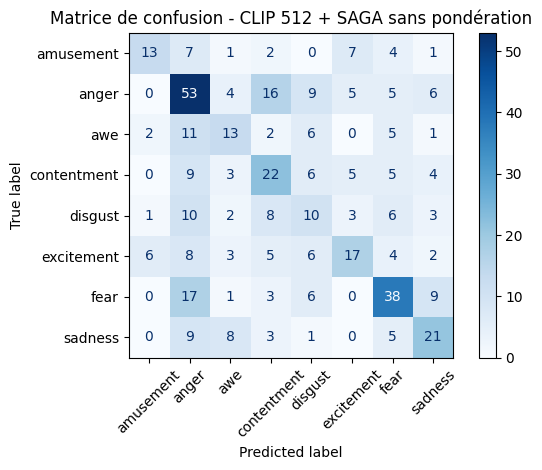

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matrice_clip_sans_poids = confusion_matrix(
    y_dev,
    predictions_clip_512_sans_poids,
    labels=modele_clip_512_sans_poids.classes_
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice_clip_sans_poids,
    display_labels=modele_clip_512_sans_poids.classes_
)

affichage.plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion - CLIP 512 + SAGA sans pondération")
plt.tight_layout()
plt.show()

Le modèle reconnaît le mieux anger (53 clips correctement classés), suivi de fear (38), tandis que disgust est souvent confondu avec anger et contentment. On observe aussi une confusion entre anger et contentment (16 clips), ainsi qu’entre fear et anger (17 clips). Ces résultats montrent que le modèle distingue certaines émotions,

In [ ]:
from sklearn.metrics import classification_report

print("Rapport de classification CLIP 512")
print(classification_report(
    y_dev,
    predictions_clip_512_sans_poids,
    zero_division=0
))

Rapport de classification CLIP 512
              precision    recall  f1-score   support

   amusement       0.59      0.37      0.46        35
       anger       0.43      0.54      0.48        98
         awe       0.37      0.33      0.35        40
 contentment       0.36      0.41      0.38        54
     disgust       0.23      0.23      0.23        43
  excitement       0.46      0.33      0.39        51
        fear       0.53      0.51      0.52        74
     sadness       0.45      0.45      0.45        47

    accuracy                           0.42       442
   macro avg       0.43      0.40      0.41       442
weighted avg       0.43      0.42      0.42       442



Le modèle obtient un F1-score de 0,52 pour fear et de 0,48 pour anger, ce qui montre qu’il reconnaît mieux ces émotions. En revanche, disgust est l’émotion la plus difficile à identifier, avec un F1-score de 0,23. Avec une Accuracy de 42,3 % et un F1-macro de 0,41

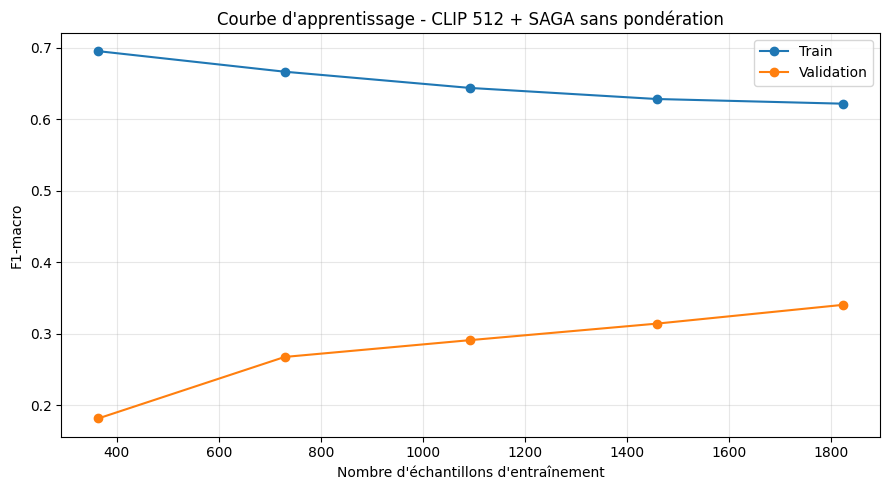

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedGroupKFold

tailles, scores_train, scores_val = learning_curve(
    modele_clip_512_sans_poids,
    X_train_512,
    y_train,
    groups=film_train,
    cv=StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train = scores_train.mean(axis=1)
moyenne_val = scores_val.mean(axis=1)

plt.figure(figsize=(9, 5))

plt.plot(tailles, moyenne_train, marker="o", label="Train")
plt.plot(tailles, moyenne_val, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprentissage - CLIP 512 + SAGA sans pondération")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La courbe d'apprentissage montre que le F1-macro de validation augmente progressivement jusqu'à environ 0,34 lorsque la taille du jeu d'entraînement augmente. En parallèle, le score d'entraînement diminue de 0,69 à 0,62. L'écart entre les deux courbes se réduit légèrement, ce qui indique une amélioration de la généralisation du modèle avec davantage de données.

Parmi les modèles de régression logistique testés, le modèle CLIP 512 avec le solveur SAGA et sans pondération des classes a obtenu les meilleures performances.

# Sauvegarde modele final

In [ ]:
import joblib

joblib.dump(
    modele_clip_512_sans_poids,
    dossier_features / "modele_video_clip_512_sans_poids.joblib"
)

print("Modèle sauvegardé !")

Modèle sauvegardé !


In [ ]:
import pandas as pd

fichier_ids = base / "ids_video.csv"
ids_existants = pd.read_csv(
    fichier_ids,
    dtype=str
)["video_id"].tolist()

In [ ]:
X_test_512 = X_video[labels["split"].values == "test", :512]
y_test = labels.loc[labels["split"] == "test", "emotion"].values

In [ ]:
print("Dimensions des features :")
print("Train :", X_train_512.shape)
print("Dev   :", X_dev_512.shape)
print("Test  :", X_test_512.shape)

print("\nNombre de vidéos dans labels :")
print("Train :", (labels["split"] == "train").sum())
print("Dev   :", (labels["split"] == "dev").sum())
print("Test  :", (labels["split"] == "test").sum())

Dimensions des features :
Train : (2207, 512)
Dev   : (442, 512)
Test  : (439, 512)

Nombre de vidéos dans labels :
Train : 2207
Dev   : 442
Test  : 439


In [ ]:
probas_video_dev = modele_clip_512_sans_poids.predict_proba(X_dev_512)
probas_video_test = modele_clip_512_sans_poids.predict_proba(X_test_512)

print("Probabilités vidéo Dev :", probas_video_dev.shape)
print("Probabilités vidéo Test :", probas_video_test.shape)

print("Somme des probabilités Dev :",np.allclose(probas_video_dev.sum(axis=1), 1))

print("Somme des probabilités Test :",np.allclose(probas_video_test.sum(axis=1), 1))

Probabilités vidéo Dev : (442, 8)
Probabilités vidéo Test : (439, 8)
Somme des probabilités Dev : True
Somme des probabilités Test : True


In [ ]:
# Sauvegarder les probabilités
np.save(dossier_features / "probas_video_dev.npy", probas_video_dev)
np.save(dossier_features / "probas_video_test.npy", probas_video_test)

# Sauvegarder les identifiants correspondants
labels.loc[labels["split"] == "dev", ["video_id"]].to_csv(dossier_features / "ids_video_dev.csv", index=False)
labels.loc[labels["split"] == "test", ["video_id"]].to_csv(dossier_features / "ids_video_test.csv", index=False)

# Sauvegarder l'ordre des classes
np.save(dossier_features / "classes_video.npy",modele_clip_512_sans_poids.classes_)

print("Fichiers vidéo sauvegardés avec succès !")

Fichiers vidéo sauvegardés avec succès !


In [ ]:
ids_dev = pd.read_csv(dossier_features / "ids_video_dev.csv",dtype=str)["video_id"].values
ids_test = pd.read_csv(dossier_features / "ids_video_test.csv",dtype=str)["video_id"].values

probs_dev = np.load(dossier_features / "probas_video_dev.npy")
probs_test = np.load(dossier_features / "probas_video_test.npy")

classes = np.load(dossier_features / "classes_video.npy",allow_pickle=True)

df_probas_dev = pd.DataFrame(probs_dev, columns=classes)
df_probas_dev.insert(0, "video_id", ids_dev)
df_probas_test = pd.DataFrame(probs_test, columns=classes)
df_probas_test.insert(0, "video_id", ids_test)

df_probas_dev.to_csv(dossier_features / "probas_video_dev.csv",index=False)
df_probas_test.to_csv(dossier_features / "probas_video_test.csv",index=False)

In [ ]:
# Calculer les probabilités du train
probas_video_train = modele_clip_512_sans_poids.predict_proba(X_train_512)

# Récupérer les IDs du train
ids_train = labels.loc[labels["split"] == "train", "video_id"].values

# Créer le DataFrame
df_probas_train = pd.DataFrame(
    probas_video_train,
    columns=modele_clip_512_sans_poids.classes_
)

df_probas_train.insert(0, "video_id", ids_train)

# Sauvegarder le CSV
df_probas_train.to_csv(
    dossier_features / "probas_video_train.csv",
    index=False
)

print(df_probas_train.shape)

(2207, 9)


Telechargement des embadding de Clip 512 du molele choisi

In [ ]:
print("Meanstd :", X_video_meanstd.shape)
X_video_512 = X_video_meanstd[:, :512]
print("X_video_512 :", X_video_512.shape)
np.save(dossier_features / "X_video_512.npy", X_video_512)
test = np.load(dossier_features / "X_video_512.npy")
print("Fichier sauvegardé :", test.shape)

Meanstd : (3088, 1024)
X_video_512 : (3088, 512)
Fichier sauvegardé : (3088, 512)


In [ ]:
for f in dossier_features.glob("*.npy"):
    arr = np.load(f, allow_pickle=True)
    print(f.name, arr.shape)

X_video_baseline.npy (3088, 141)
ids_video_resnet.npy (3088,)
X_video_resnet_mean.npy (3088, 512)
X_video_meanstd.npy (3088, 1024)
probas_video_dev.npy (442, 8)
probas_video_test.npy (439, 8)
classes_video.npy (8,)
X_video_512.npy (3088, 512)
